In [1]:
!pip install transformers accelerate -q

import re, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
random.seed(42)

MOCK_MODE = True   # Set to False once you've generated real plans in Task 1

USER_REQUEST = (
    "I need to travel from Kolkata to IIT Bhubaneswar for a PW course meet. "
    "I want a budget-friendly plan. I prefer train travel if possible. "
    "I should reach IIT Bhubaneswar before 9 AM. Avoid unsafe late-night waiting. "
    "Suggest a simple travel plan with backup options."
)

In [2]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

def load_model(model_name=MODEL_NAME):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(
        model_name, torch_dtype=torch.float16, device_map="auto"
    )
    return tokenizer, model


def generate_plans(tokenizer, model, user_request, num_plans=3, max_new_tokens=300):
    """Generate multiple candidate plans via sampling (different seeds/temperature)."""
    messages = [
        {"role": "system", "content": "You are a helpful travel-planning assistant for students."},
        {"role": "user", "content": user_request},
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    plans = []
    for i in range(num_plans):
        torch.manual_seed(i * 17 + 1)
        output = model.generate(
            **inputs, max_new_tokens=max_new_tokens,
            do_sample=True, temperature=0.8, top_p=0.9,
        )
        text = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        plans.append(text.strip())
    return plans


if not MOCK_MODE:
    tokenizer, model = load_model()
    generated_plans = generate_plans(tokenizer, model, USER_REQUEST, num_plans=3)
    for i, p in enumerate(generated_plans, 1):
        print(f"\n===== Candidate Plan {i} =====\n{p}")

In [3]:
MOCK_PLANS = [
    # Plan 1: Good - train, safe timing, clear steps, backup included, budget
    """Take the overnight Dhauli/Falaknuma-style train from Howrah Station at 10:30 PM,
    which arrives at Bhubaneswar Station around 6:30 AM (approx cost Rs 400 in sleeper class).
    Wait inside the well-lit station hall, not outside, until 7:00 AM.
    Then take a shared auto or app cab (approx Rs 150) to IIT Bhubaneswar, arriving by 7:45 AM,
    well before the 9 AM deadline. Backup option: if the train is delayed, take the next available
    train or a state bus from Esplanade, which runs every 2 hours.""",

    # Plan 2: Bad - vague, no specifics, unsafe late night waiting implied
    """Just go to the station and take whatever train is available. It should probably work out fine,
    you might have to wait a bit but it will be okay. Travel overnight and figure out the rest when
    you get there. Should be cheap enough.""",

    # Plan 3: Medium - flight based (not train preference), fast but expensive
    """Book a flight from Kolkata Airport to Bhubaneswar Airport departing 6:00 AM, arriving 7:00 AM
    (approx cost Rs 3500). Take a prepaid cab (approx Rs 400) directly to IIT Bhubaneswar,
    arriving around 8:00 AM. This is fast and reliable but costs significantly more than a train.""",

    # Plan 4: Bad - unsafe late night waiting, no backup
    """Take a late night bus from Kolkata at 11 PM that arrives at Bhubaneswar bus stand around
    5 AM. Wait alone at the bus stand for a couple hours in the dark until transport is available
    around 7 AM, then find an auto to IIT Bhubaneswar. No backup plan needed, this should be fine.""",

    # Plan 5: Good - train, budget, clear, backup, safe
    """Take the Howrah-Bhubaneswar overnight train departing 9:50 PM, arriving Bhubaneswar Station
    5:45 AM (sleeper class, approx Rs 380). Wait inside the station's designated waiting area, which is
    staffed and lit through the night, until 7:30 AM. Take a shared cab (approx Rs 120) to reach IIT
    Bhubaneswar by 8:15 AM. Backup option: an alternate morning train (Puri Express) departs Howrah
    at 6:30 AM and reaches by early afternoon if the overnight train is missed, or a Volvo bus service
    is available as a fallback from Esplanade bus terminus.""",
]

plans = generated_plans if not MOCK_MODE else MOCK_PLANS
print(f"Using {len(plans)} candidate plans ({'LLM-generated' if not MOCK_MODE else 'mock'}).")

Using 5 candidate plans (mock).


In [4]:
WEIGHTS = {
    "budget_friendly": 0.20, "reaches_before_9am": 0.20, "train_preference": 0.15,
    "safety": 0.20, "clarity": 0.15, "backup_options": 0.10,
}
VAGUE_PHRASES = ["probably", "should work out", "figure out", "whatever", "maybe",
                  "should be fine", "should be okay", "not sure", "somehow"]
UNSAFE_PHRASES = ["wait alone", "in the dark", "no backup", "late night bus", "dark until"]
SAFE_PHRASES = ["lit", "staffed", "well-lit", "designated waiting area", "inside the station"]


def score_budget(text):
    costs = [int(x) for x in re.findall(r"Rs\.?\s?(\d+)", text)]
    if not costs:
        return 40
    total_cost = sum(costs)
    if total_cost <= 600: return 100
    elif total_cost <= 1500: return 65
    else: return 25


def score_before_9am(text):
    matches = re.findall(r"(\d{1,2}):(\d{2})\s?AM", text)
    if not matches:
        return 30
    hours = [int(h) for h, m in matches]
    latest_hour = max(hours)
    if latest_hour < 9: return 100
    elif latest_hour == 9: return 60
    else: return 20


def score_train_preference(text):
    t = text.lower()
    if "train" in t and "flight" not in t: return 100
    elif "train" in t: return 60
    elif "bus" in t: return 40
    else: return 10


def score_safety(text):
    t = text.lower()
    score = 60
    for p in UNSAFE_PHRASES:
        if p in t: score -= 30
    for p in SAFE_PHRASES:
        if p in t: score += 20
    return max(0, min(100, score))


def score_clarity(text):
    t = text.lower()
    score = 70
    for p in VAGUE_PHRASES:
        if p in t: score -= 20
    num_times = len(re.findall(r"\d{1,2}:\d{2}", text))
    num_costs = len(re.findall(r"Rs\.?\s?\d+", text))
    score += min(20, (num_times + num_costs) * 4)
    return max(0, min(100, score))


def score_backup(text):
    t = text.lower()
    if "backup" in t or "alternate" in t or "fallback" in t: return 100
    elif "no backup" in t: return 0
    else: return 20


def reward_function(text):
    scores = {
        "budget_friendly": score_budget(text), "reaches_before_9am": score_before_9am(text),
        "train_preference": score_train_preference(text), "safety": score_safety(text),
        "clarity": score_clarity(text), "backup_options": score_backup(text),
    }
    scores["total_reward"] = round(sum(scores[k] * WEIGHTS[k] for k in WEIGHTS), 2)
    return scores


for i, plan in enumerate(plans, 1):
    s = reward_function(plan)
    print(f"Plan {i}: total_reward = {s['total_reward']}  |  {s}")

Plan 1: total_reward = 98.5  |  {'budget_friendly': 100, 'reaches_before_9am': 100, 'train_preference': 100, 'safety': 100, 'clarity': 90, 'backup_options': 100, 'total_reward': 98.5}
Plan 2: total_reward = 44.5  |  {'budget_friendly': 40, 'reaches_before_9am': 30, 'train_preference': 100, 'safety': 60, 'clarity': 10, 'backup_options': 20, 'total_reward': 44.5}
Plan 3: total_reward = 61.5  |  {'budget_friendly': 25, 'reaches_before_9am': 100, 'train_preference': 60, 'safety': 60, 'clarity': 90, 'backup_options': 20, 'total_reward': 61.5}
Plan 4: total_reward = 37.5  |  {'budget_friendly': 40, 'reaches_before_9am': 30, 'train_preference': 40, 'safety': 0, 'clarity': 50, 'backup_options': 100, 'total_reward': 37.5}
Plan 5: total_reward = 98.5  |  {'budget_friendly': 100, 'reaches_before_9am': 100, 'train_preference': 100, 'safety': 100, 'clarity': 90, 'backup_options': 100, 'total_reward': 98.5}


In [5]:
scored = [(i + 1, plan, reward_function(plan)["total_reward"]) for i, plan in enumerate(plans)]
ranked = sorted(scored, key=lambda x: x[2], reverse=True)

print("===== Plan Ranking (highest reward first) =====")
for rank, (plan_id, plan, reward) in enumerate(ranked, 1):
    preview = plan.strip().replace("\n", " ")[:80]
    print(f"Rank {rank}: Plan {plan_id}  |  reward = {reward}  |  \"{preview}...\"")

===== Plan Ranking (highest reward first) =====
Rank 1: Plan 1  |  reward = 98.5  |  "Take the overnight Dhauli/Falaknuma-style train from Howrah Station at 10:30 PM,..."
Rank 2: Plan 5  |  reward = 98.5  |  "Take the Howrah-Bhubaneswar overnight train departing 9:50 PM, arriving Bhubanes..."
Rank 3: Plan 3  |  reward = 61.5  |  "Book a flight from Kolkata Airport to Bhubaneswar Airport departing 6:00 AM, arr..."
Rank 4: Plan 2  |  reward = 44.5  |  "Just go to the station and take whatever train is available. It should probably ..."
Rank 5: Plan 4  |  reward = 37.5  |  "Take a late night bus from Kolkata at 11 PM that arrives at Bhubaneswar bus stan..."


True (normalized) plan rewards: [0.985 0.445 0.615 0.375 0.985]
Best plan by reward: Plan 1

Iter  0 | chose Plan 2 | reward=0.423 | advantage=-0.077 | critic V(s)=0.492 | policy probs=[0.2   0.198 0.2   0.2   0.2  ]
Iter 10 | chose Plan 3 | reward=0.602 | advantage=+0.015 | critic V(s)=0.589 | policy probs=[0.25  0.175 0.194 0.188 0.193]
Iter 20 | chose Plan 2 | reward=0.501 | advantage=-0.161 | critic V(s)=0.645 | policy probs=[0.297 0.165 0.187 0.164 0.187]
Iter 30 | chose Plan 4 | reward=0.371 | advantage=-0.390 | critic V(s)=0.722 | policy probs=[0.329 0.158 0.174 0.139 0.2  ]
Iter 40 | chose Plan 3 | reward=0.607 | advantage=-0.095 | critic V(s)=0.692 | policy probs=[0.359 0.148 0.163 0.121 0.208]
Iter 50 | chose Plan 5 | reward=1.012 | advantage=+0.210 | critic V(s)=0.823 | policy probs=[0.39  0.132 0.151 0.106 0.222]
Iter 60 | chose Plan 5 | reward=0.985 | advantage=+0.141 | critic V(s)=0.857 | policy probs=[0.409 0.111 0.145 0.102 0.234]
Iter 70 | chose Plan 1 | reward=1.013 |

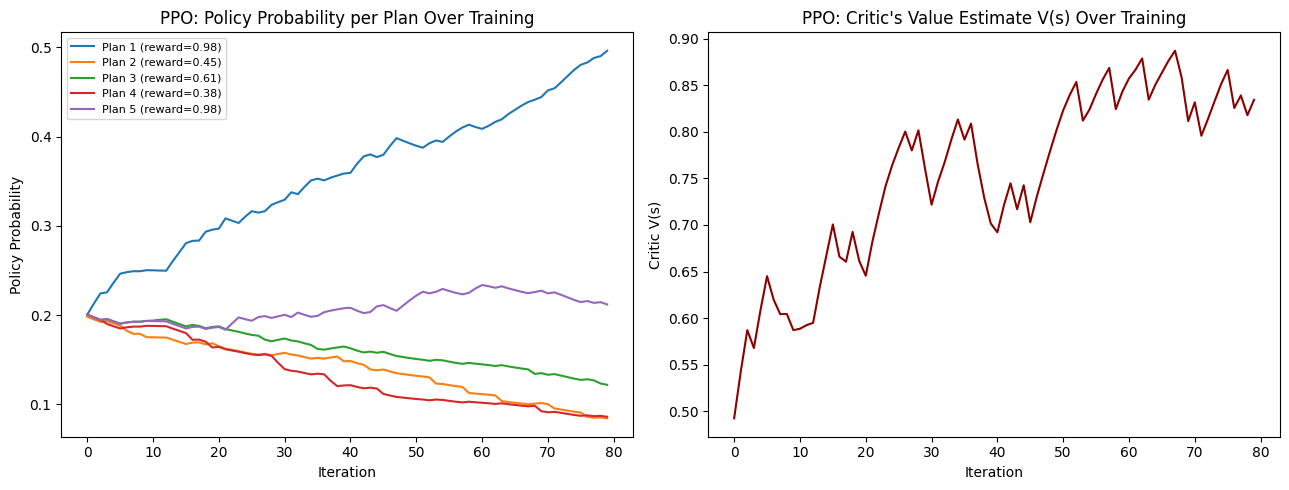

In [6]:
N_ACTIONS = len(plans)
TRUE_REWARDS = np.array([reward_function(p)["total_reward"] / 100 for p in plans])

actor_logits = np.zeros(N_ACTIONS)
critic_value = 0.5
LR_ACTOR, LR_CRITIC, CLIP_EPS, N_ITERATIONS = 0.15, 0.10, 0.2, 80

def softmax(logits):
    exp = np.exp(logits - np.max(logits))
    return exp / exp.sum()

prob_history, critic_history = [], []

print("True (normalized) plan rewards:", np.round(TRUE_REWARDS, 3))
print(f"Best plan by reward: Plan {np.argmax(TRUE_REWARDS) + 1}\n")

for it in range(N_ITERATIONS):
    old_probs = softmax(actor_logits)
    action = np.random.choice(N_ACTIONS, p=old_probs)
    reward = TRUE_REWARDS[action] + np.random.normal(0, 0.02)
    advantage = reward - critic_value

    prob_ratio = old_probs[action] / (old_probs[action] + 1e-8)
    clipped_ratio = np.clip(prob_ratio, 1 - CLIP_EPS, 1 + CLIP_EPS)
    surrogate = min(prob_ratio * advantage, clipped_ratio * advantage)

    grad = np.zeros(N_ACTIONS)
    grad[action] = surrogate
    actor_logits = actor_logits + LR_ACTOR * grad
    critic_value = critic_value + LR_CRITIC * (reward - critic_value)

    prob_history.append(softmax(actor_logits))
    critic_history.append(critic_value)

    if it % 10 == 0 or it == N_ITERATIONS - 1:
        probs = softmax(actor_logits)
        print(f"Iter {it:2d} | chose Plan {action+1} | reward={reward:.3f} | "
              f"advantage={advantage:+.3f} | critic V(s)={critic_value:.3f} | "
              f"policy probs={np.round(probs, 3)}")

final_probs = softmax(actor_logits)
print(f"\nFinal learned policy (probability per plan): {np.round(final_probs, 3)}")
print(f"Policy now most strongly favors: Plan {np.argmax(final_probs) + 1}")

prob_history = np.array(prob_history)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i in range(N_ACTIONS):
    axes[0].plot(prob_history[:, i], label=f"Plan {i+1} (reward={TRUE_REWARDS[i]:.2f})")
axes[0].set_title("PPO: Policy Probability per Plan Over Training")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Policy Probability"); axes[0].legend(fontsize=8)
axes[1].plot(critic_history, color="darkred")
axes[1].set_title("PPO: Critic's Value Estimate V(s) Over Training")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Critic V(s)")
plt.tight_layout()
plt.savefig("ppo_training_curves.png", dpi=150)
plt.show()

In [7]:
LOCATIONS = ["Kolkata", "InTransit", "BhubaneswarStation", "IIT_Bhubaneswar"]
TIME_STATUSES = ["on_time", "at_risk", "delayed"]
BUDGET_STATUSES = ["within_budget", "over_budget"]
ACTIONS = ["train", "bus", "cab", "wait", "backup"]
GOAL_LOCATION = "IIT_Bhubaneswar"

def all_states():
    return [(loc, t, b) for loc in LOCATIONS for t in TIME_STATUSES for b in BUDGET_STATUSES]

def is_terminal(state):
    return state[0] == GOAL_LOCATION

def step(state, action):
    loc, time_status, budget_status = state
    if is_terminal(state):
        return state, 0, True
    reward = -5
    next_loc, next_time, next_budget = loc, time_status, budget_status

    if action == "train":
        idx = LOCATIONS.index(loc)
        next_loc = LOCATIONS[min(idx + 1, len(LOCATIONS) - 1)]
        if random.random() < 0.15:
            next_time = "at_risk" if time_status == "on_time" else "delayed"
            reward -= 20
    elif action == "bus":
        idx = LOCATIONS.index(loc)
        next_loc = LOCATIONS[min(idx + 1, len(LOCATIONS) - 1)]
        if random.random() < 0.30:
            next_time = "at_risk" if time_status == "on_time" else "delayed"
            reward -= 20
    elif action == "cab":
        idx = LOCATIONS.index(loc)
        next_loc = LOCATIONS[min(idx + 1, len(LOCATIONS) - 1)]
        next_budget = "over_budget"
        reward -= 15
    elif action == "wait":
        if time_status in ("at_risk", "delayed"):
            reward -= 30
        next_time = "delayed" if time_status == "at_risk" else time_status
    elif action == "backup":
        idx = LOCATIONS.index(loc)
        next_loc = LOCATIONS[min(idx + 1, len(LOCATIONS) - 1)]
        next_time = "on_time" if time_status != "delayed" else "at_risk"
        next_budget = "over_budget"
        reward -= 10

    next_state = (next_loc, next_time, next_budget)
    if next_loc == GOAL_LOCATION:
        if next_time == "on_time" and next_budget == "within_budget": reward += 100
        elif next_time == "on_time": reward += 40
        elif next_time == "at_risk": reward += 10
        else: reward -= 10

    done = next_loc == GOAL_LOCATION
    return next_state, reward, done


Q = {(s, a): 0.0 for s in all_states() for a in ACTIONS}
ALPHA, GAMMA, EPSILON = 0.1, 0.9, 0.2

def choose_action(state, epsilon=EPSILON):
    if random.random() < epsilon:
        return random.choice(ACTIONS)
    q_vals = {a: Q[(state, a)] for a in ACTIONS}
    return max(q_vals, key=q_vals.get)

def q_update(state, action, reward, next_state, done):
    old_q = Q[(state, action)]
    target = reward if done else reward + GAMMA * max(Q[(next_state, a)] for a in ACTIONS)
    Q[(state, action)] = old_q + ALPHA * (target - old_q)
    return old_q, Q[(state, action)]


start_state = ("Kolkata", "on_time", "within_budget")

print("===== Manually tracing the first 5 Q-table update steps =====\n")
state = start_state
for step_num in range(1, 6):
    action = choose_action(state)
    next_state, reward, done = step(state, action)
    old_q, new_q = q_update(state, action, reward, next_state, done)
    print(f"Step {step_num}: state={state}, action='{action}' -> next_state={next_state}, reward={reward}")
    print(f"          Q[{state}, '{action}']: {old_q:.3f} -> {new_q:.3f}\n")
    state = next_state
    if done:
        print("  (reached goal, resetting to start state)\n")
        state = start_state

print("===== Training for many episodes to let the Q-table converge =====")
N_EPISODES = 3000
for ep in range(N_EPISODES):
    state = start_state
    for _ in range(15):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        q_update(state, action, reward, next_state, done)
        state = next_state
        if done:
            break

print(f"\nTrained over {N_EPISODES} episodes.\nLearned best action per key state (greedy policy):")
for loc in LOCATIONS[:-1]:
    for t in TIME_STATUSES:
        for b in BUDGET_STATUSES:
            s = (loc, t, b)
            best_a = max(ACTIONS, key=lambda a: Q[(s, a)])
            print(f"  State {s}: best action = '{best_a}'  (Q={Q[(s, best_a)]:.2f})")

===== Manually tracing the first 5 Q-table update steps =====

Step 1: state=('Kolkata', 'on_time', 'within_budget'), action='train' -> next_state=('InTransit', 'at_risk', 'within_budget'), reward=-25
          Q[('Kolkata', 'on_time', 'within_budget'), 'train']: 0.000 -> -2.500

Step 2: state=('InTransit', 'at_risk', 'within_budget'), action='train' -> next_state=('BhubaneswarStation', 'at_risk', 'within_budget'), reward=-5
          Q[('InTransit', 'at_risk', 'within_budget'), 'train']: 0.000 -> -0.500

Step 3: state=('BhubaneswarStation', 'at_risk', 'within_budget'), action='train' -> next_state=('IIT_Bhubaneswar', 'at_risk', 'within_budget'), reward=5
          Q[('BhubaneswarStation', 'at_risk', 'within_budget'), 'train']: 0.000 -> 0.500

  (reached goal, resetting to start state)

Step 4: state=('Kolkata', 'on_time', 'within_budget'), action='bus' -> next_state=('InTransit', 'at_risk', 'within_budget'), reward=-25
          Q[('Kolkata', 'on_time', 'within_budget'), 'bus']: 0.000

In [8]:
dpo_pairs = [
    {
        "prompt": USER_REQUEST,
        "chosen": (
            "Take the Howrah-Bhubaneswar overnight train departing 9:50 PM, arriving "
            "Bhubaneswar Station 5:45 AM (sleeper class, approx Rs 380). Wait inside the "
            "station's staffed, well-lit waiting area until 7:30 AM. Take a shared cab "
            "(approx Rs 120) to reach IIT Bhubaneswar by 8:15 AM. Backup: an alternate "
            "morning train or Volvo bus from Esplanade is available if this train is missed."
        ),
        "rejected": (
            "Just go to the station and take whatever train is available. It should "
            "probably work out fine, you might have to wait a bit but it will be okay. "
            "Travel overnight and figure out the rest when you get there."
        ),
    },
    {
        "prompt": USER_REQUEST,
        "chosen": (
            "Board the 10:30 PM train from Howrah (sleeper class, ~Rs 400), arriving "
            "Bhubaneswar 6:30 AM. Wait inside the lit station hall, then take a shared "
            "auto (~Rs 150) to IIT Bhubaneswar, reaching by 7:45 AM. Backup: next available "
            "train or the Esplanade state bus every 2 hours."
        ),
        "rejected": (
            "Take a late night bus from Kolkata at 11 PM arriving around 5 AM. Wait alone "
            "at the bus stand for a couple hours in the dark until transport is available. "
            "No backup plan needed, this should be fine."
        ),
    },
    {
        "prompt": USER_REQUEST,
        "chosen": (
            "Train from Howrah at 9:50 PM, sleeper class ~Rs 380, arriving Bhubaneswar "
            "5:45 AM. Wait in the staffed waiting hall, then shared cab (~Rs 120) to "
            "campus by 8:15 AM. Backup: Puri Express morning train or Volvo bus fallback."
        ),
        "rejected": (
            "Book a flight departing 6 AM (~Rs 3500), then a prepaid cab (~Rs 400) to "
            "campus, arriving around 8 AM. This is fast but ignores the budget-friendly "
            "and train-preference constraints entirely."
        ),
    },
    {
        "prompt": USER_REQUEST,
        "chosen": (
            "Overnight train from Howrah at 10:30 PM (~Rs 400 sleeper), reaching "
            "Bhubaneswar 6:30 AM. Wait safely inside the station, then shared auto "
            "(~Rs 150) to IIT Bhubaneswar by 7:45 AM. Backup option: alternate train or "
            "state bus every 2 hours if delayed."
        ),
        "rejected": (
            "Take any overnight transport, wait near the station until something shows "
            "up, and head to the campus whenever transport is available. Cost and safety "
            "will probably sort themselves out."
        ),
    },
]

dpo_df = pd.DataFrame(dpo_pairs)
print(dpo_df.to_string(index=False, max_colwidth=60))

with open("dpo_preference_dataset.json", "w") as f:
    json.dump(dpo_pairs, f, indent=2)
dpo_df.to_csv("dpo_preference_dataset.csv", index=False)
print(f"\nSaved {len(dpo_pairs)} preference pairs to dpo_preference_dataset.json / .csv")

                                                      prompt                                                       chosen                                                     rejected
I need to travel from Kolkata to IIT Bhubaneswar for a PW... Take the Howrah-Bhubaneswar overnight train departing 9:5... Just go to the station and take whatever train is availab...
I need to travel from Kolkata to IIT Bhubaneswar for a PW... Board the 10:30 PM train from Howrah (sleeper class, ~Rs ... Take a late night bus from Kolkata at 11 PM arriving arou...
I need to travel from Kolkata to IIT Bhubaneswar for a PW... Train from Howrah at 9:50 PM, sleeper class ~Rs 380, arri... Book a flight departing 6 AM (~Rs 3500), then a prepaid c...
I need to travel from Kolkata to IIT Bhubaneswar for a PW... Overnight train from Howrah at 10:30 PM (~Rs 400 sleeper)... Take any overnight transport, wait near the station until...

Saved 4 preference pairs to dpo_preference_dataset.json / .csv


In [9]:
comparison = pd.DataFrame({
    "Method": ["RLHF (full pipeline)", "PPO", "DPO", "Q-learning"],
    "What it needs": [
        "Human preference labels -> reward model -> RL fine-tuning loop",
        "A reward model/function + on-policy rollouts + actor & critic",
        "Just (chosen, rejected) preference pairs -- no reward model, no rollouts",
        "A well-defined state/action space + reward per transition (needs an MDP)",
    ],
    "Implementation difficulty": ["Hardest", "Hard", "Easiest", "Medium"],
    "Stability": ["Depends on reward model quality", "Can be unstable (needs careful clipping/tuning)",
                  "Very stable (simple classification-like loss)", "Stable for small discrete state spaces"],
    "Best fit for this task": [
        "Overkill for a small travel assistant -- needs a full annotation + RL infra",
        "Reasonable if you want the LLM itself to keep improving via reward signal",
        "Best fit: directly nudges the LLM towards safer/clearer plans using cheap preference pairs",
        "Not suited to free-form text generation -- great for the discrete route/mode decision sub-problem",
    ],
})
pd.set_option("display.max_colwidth", 80)
print(comparison.to_string(index=False))

              Method                                                            What it needs Implementation difficulty                                       Stability                                                                            Best fit for this task
RLHF (full pipeline)           Human preference labels -> reward model -> RL fine-tuning loop                   Hardest                 Depends on reward model quality                       Overkill for a small travel assistant -- needs a full annotation + RL infra
                 PPO            A reward model/function + on-policy rollouts + actor & critic                      Hard Can be unstable (needs careful clipping/tuning)                         Reasonable if you want the LLM itself to keep improving via reward signal
                 DPO Just (chosen, rejected) preference pairs -- no reward model, no rollouts                   Easiest   Very stable (simple classification-like loss)        Best fit: directly nudges t